# Training models in two phases with SVI

In [1]:
import statistics
import scipy.stats as stats
import logging
from pyts.datasets import load_gunpoint
import matplotlib.pyplot as plt
import math
from typing import Optional
import itertools
import random
import copy

import seaborn as sns
import pandas as pd

import torch
import pyro
from pyro.infer import Predictive
import pyro.distributions as dist
from pyro.distributions import constraints

In [2]:
param_store = pyro.get_param_store()

In [3]:
def model(y1: torch.Tensor, y2: torch.Tensor):
    theta = pyro.sample("theta", dist.Normal(0,1))
    mu = pyro.sample("mu", dist.Normal(theta, 1))
    obs1 = pyro.sample("y1", dist.Normal(theta, 1), obs = y1)
    obs2 = pyro.sample("y2", dist.Normal(mu, 1), obs = y2)

def guide(*args, **kwargs):
    theta_loc = pyro.param("theta_loc", torch.tensor(0.0))
    theta_scale = pyro.param("theta_scale", torch.tensor(1.0), constraint = constraints.positive)
    mu_loc = pyro.param("mu_loc", torch.tensor(0.0))
    mu_scale = pyro.param("mu_scale", torch.tensor(1.0), constraint = constraints.positive)
    theta = pyro.sample("theta", dist.Normal(theta_loc, theta_scale))
    mu = pyro.sample("mu", dist.Normal(mu_loc, mu_scale))


In [6]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, params = None, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    best_loss = torch.inf
    if params is None:
        with pyro.get_param_store().scope() as params:
            pass
    best_params = copy.deepcopy(params)
    while nonimproved < max_nonimproved:
        with pyro.get_param_store().scope(params):
            loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            if current_loss < best_loss:
                best_loss = current_loss
                best_params = copy.deepcopy(params)
                params_updated = True
            else:
                params_updated = False
            current_loss_std = statistics.stdev(losses[-check_interval:])
            reg = stats.linregress(range(check_interval), losses[-check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            print("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}){} {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, ' +'*params_updated, '*'*nonimproved))
            #logging.info("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
    return best_params, losses

In [7]:
def test_expose_factory(name: str):
    def test_expose(msg) -> bool:
        print(f"{name}, {msg}")
        return True
    return test_expose

model_blocked = pyro.poutine.block(model, expose_fn=test_expose_factory("model"))
guide_blocked = pyro.poutine.block(guide, expose_fn=test_expose_factory("guide"))

In [8]:
def expose_first_layer(msg):
    if msg['type'] == 'param':
        if msg['name'] in ['theta_loc', 'theta_scale']:
            return True
    elif msg['type'] == 'sample':
        if msg['name'] in ['theta','y1']:
            return True
    return False

def expose_second_layer(msg):
    if msg['type'] == 'param':
        if msg['name'] in ['mu_loc', 'mu_scale']:
            return True
    elif msg['type'] == 'sample':
        return True
        # if msg['name'] in ['mu','y2']:
        #     return True
    return False

model_first = pyro.poutine.block(model, expose_fn=expose_first_layer)
model_second = pyro.poutine.block(model, expose_fn=expose_second_layer)
guide_first = pyro.poutine.block(guide, expose_fn=expose_first_layer)
guide_second = pyro.poutine.block(guide, expose_fn=expose_second_layer)


In [9]:
y1 = torch.tensor(5.0)
y2 = torch.tensor(-5.0)

adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
svi = pyro.infer.SVI(model, guide, adam, elbo)
svi_second = pyro.infer.SVI(model_second, guide_second, adam, elbo)
svi_first = pyro.infer.SVI(model_first, guide_first, adam, elbo)


Step 1000, Elbo loss: 24.9 +/- 10.2 (slope = -5.874 +/- 1.050 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 21.3 +/- 4.4 (slope = -1.847 +/- 0.473 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 20.5 +/- 1.9 (slope = -0.184 +/- 0.204 loss/k-iter, p-value = 0.035) + 
Step 4000, Elbo loss: 20.3 +/- 1.0 (slope = -0.041 +/- 0.113 loss/k-iter, p-value = 0.234) + *
Step 5000, Elbo loss: 20.2 +/- 0.8 (slope = 0.007 +/- 0.093 loss/k-iter, p-value = 0.563) + **
Step 6000, Elbo loss: 20.3 +/- 0.9 (slope = -0.069 +/- 0.094 loss/k-iter, p-value = 0.071) 
Step 7000, Elbo loss: 20.3 +/- 0.8 (slope = -0.041 +/- 0.083 loss/k-iter, p-value = 0.163) *
Step 8000, Elbo loss: 20.2 +/- 0.9 (slope = -0.050 +/- 0.096 loss/k-iter, p-value = 0.147) + **
Step 9000, Elbo loss: 20.2 +/- 0.8 (slope = -0.036 +/- 0.090 loss/k-iter, p-value = 0.209) + ***
{'theta_loc': tensor(1.0073, requires_grad=True), 'theta_scale': tensor(-0.5109, requires_grad=True), 'mu_loc': tensor(-2.0063, requires_grad=True), 

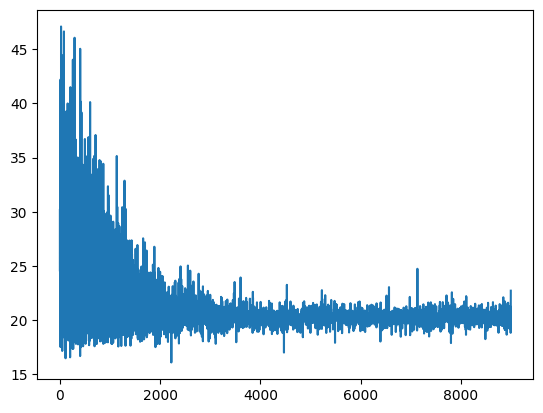

In [10]:
params_full, losses = do_svi(svi, y1, y2, params = None)
plt.plot(losses)
print(params_full['params'])

Step 1000, Elbo loss: 12.0 +/- 8.0 (slope = -2.947 +/- 0.856 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 9.2 +/- 4.6 (slope = -1.641 +/- 0.495 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 8.1 +/- 2.3 (slope = -0.732 +/- 0.247 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 7.6 +/- 1.1 (slope = -0.220 +/- 0.116 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 7.5 +/- 0.4 (slope = -0.006 +/- 0.049 loss/k-iter, p-value = 0.410) + *
Step 6000, Elbo loss: 7.5 +/- 0.2 (slope = -0.018 +/- 0.017 loss/k-iter, p-value = 0.017) + 
Step 7000, Elbo loss: 7.5 +/- 0.0 (slope = -0.002 +/- 0.005 loss/k-iter, p-value = 0.178) + *
Step 8000, Elbo loss: 7.5 +/- 0.1 (slope = 0.001 +/- 0.010 loss/k-iter, p-value = 0.562) + **
Step 9000, Elbo loss: 7.5 +/- 0.1 (slope = 0.001 +/- 0.008 loss/k-iter, p-value = 0.606) ***
{'theta_loc': tensor(2.4851, requires_grad=True), 'theta_scale': tensor(-0.3150, requires_grad=True), 'mu_loc': tensor(0., requires_grad=True), 'mu_scale': ten

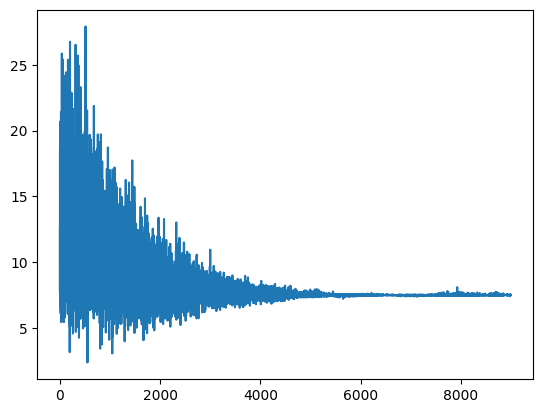

In [11]:
params_first, losses_first = do_svi(svi_first, y1, y2, params = None)
plt.plot(losses_first)
print(params_first['params'])

Step 5000, Elbo loss: 23.1 +/- 5.6 (slope = 0.003 +/- 0.055 loss/k-iter, p-value = 0.540) + *
Step 10000, Elbo loss: 23.0 +/- 5.5 (slope = 0.010 +/- 0.054 loss/k-iter, p-value = 0.641) + **
Step 15000, Elbo loss: 23.0 +/- 5.6 (slope = 0.005 +/- 0.055 loss/k-iter, p-value = 0.577) ***
{'theta_loc': tensor(2.4851, requires_grad=True), 'theta_scale': tensor(-0.3150, requires_grad=True), 'mu_loc': tensor(-1.2517, requires_grad=True), 'mu_scale': tensor(-0.3693, requires_grad=True)}


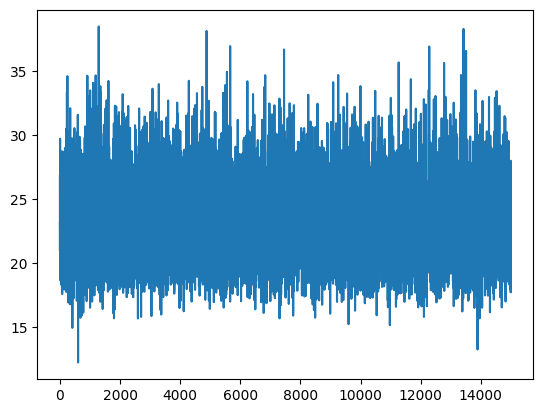

In [13]:
params_second, losses_second = do_svi(svi_second, y1, y2, params = params_first, check_interval = 5000)
plt.plot(losses_second)
print(params_second['params'])